In [ ]:
HUMAN_ACCURACY = 98.0

print("Human reference accuracy (%):", HUMAN_ACCURACY)



## 2) ⚙️ Setup & Imports

**🇷🇺** Установки (при необходимости) и импорты.  
**🇬🇧** Installs (if needed) and imports.


In [3]:
import os, math, time, random, json
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
import torchvision
import torchvision.transforms as T
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from datetime import datetime, timezone, timedelta

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)

print("Torch:", torch.__version__, "| CUDA:", torch.cuda.is_available(), "| Device:", DEVICE)

Torch: 2.10.0+cpu | CUDA: False | Device: cpu



## 3) 🧩 Assignment: Prepare Dataset (Train/Dev/Test)

**🇷🇺 Что нужно сделать:**  
Загрузите **MNIST**, разделите обучающую часть на **Train (50k)** и **Dev (10k)**,  
создайте три `DataLoader`: `train_loader`, `dev_loader`, `test_loader`. Используйте `batch_size = 128`.

**🇬🇧 What to do:**  
Load **MNIST**, split the training set into **Train (50k)** and **Dev (10k)**,  
create `train_loader`, `dev_loader`, `test_loader`. Use `batch_size = 128`.


In [4]:
transform = T.Compose([T.ToTensor()])

# 1) Load MNIST
train_full = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_ds    = torchvision.datasets.MNIST(root="./data", train=False, download=True, transform=transform)

# 2) Split into train (50k) and dev (10k)
train_size = 50_000
dev_size   = len(train_full) - train_size
train_ds, dev_ds = random_split(
    train_full, [train_size, dev_size],
    generator=torch.Generator().manual_seed(SEED)
)

# 3) Create DataLoaders
BATCH = 128
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2, pin_memory=True)
dev_loader   = DataLoader(dev_ds,   batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)

completed_data = True
print("✅ Data ready:", len(train_ds), len(dev_ds), len(test_ds))

100%|██████████| 9.91M/9.91M [00:00<00:00, 38.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.08MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.35MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.21MB/s]

✅ Data ready: 50000 10000 10000



## 4) 🧩 Assignment: Build the Model (CNN)

**🇷🇺 Что нужно сделать:**  
Реализуйте простую CNN:  
Conv(1→16)  → Conv(16→32) → Pool → FC(32×7×7→128) → FC(128→10).  
Создайте хелпер `evaluate(model, loader)` для подсчёта accuracy.

**🇬🇧 What to do:**  
Implement a small CNN:  
Conv(1→16) → Conv(16→32) → Pool → FC(32×7×7→128) → FC(128→10).  
Define an `evaluate(model, loader)` helper to compute accuracy.


In [5]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.pool  = nn.MaxPool2d(2, 2)
        self.fc1   = nn.Linear(32 * 7 * 7, 128)
        self.fc2   = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # 1x28x28 -> 16x14x14
        x = self.pool(F.relu(self.conv2(x)))  # 16x14x14 -> 32x7x7
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

def evaluate(model, loader, device=DEVICE):
    model.eval()
    y_pred, y_true = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            preds = torch.argmax(logits, dim=1)
            y_pred.extend(preds.cpu().numpy())
            y_true.extend(yb.cpu().numpy())
    return 100.0 * accuracy_score(y_true, y_pred)

completed_model = True
print("✅ Model defined.")

✅ Model defined.



## 5) 🧩 Assignment: Train Baseline & Compute Bias/Variance

**🇷🇺 Что нужно сделать:**  
1) Обучите `SmallCNN` на Train (3 эпохи),  
2) Получите точности на Train/Dev/Test,  
3) Рассчитайте: `avoidable_bias = HUMAN_ACCURACY - train_acc`, `variance = dev_acc - train_acc`.

**🇬🇧 What to do:**  
1) Train `SmallCNN` on Train (3 epochs),  
2) Compute Train/Dev/Test accuracies,  
3) Calculate: `avoidable_bias = HUMAN_ACCURACY - train_acc`, `variance = dev_acc - train_acc`.


In [6]:
import torch.optim as optim

def train_one_epoch(model, loader, opt, device=DEVICE):
    model.train()
    total_loss = 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = F.cross_entropy(logits, yb)
        loss.backward()
        opt.step()
        total_loss += loss.item() * xb.size(0)
    return total_loss / len(loader.dataset)

def train_model(epochs=3, lr=1e-3, weight_decay=0.0):
    model = SmallCNN().to(DEVICE)
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_dev, best_state = -1.0, None
    for ep in range(1, epochs+1):
        loss = train_one_epoch(model, train_loader, opt)
        dv_acc = evaluate(model, dev_loader)
        if dv_acc > best_dev:
            best_dev = dv_acc
            best_state = {k:v.cpu() for k,v in model.state_dict().items()}
        print(f"Epoch {ep:02d} | loss={loss:.4f} | dev_acc={dv_acc:.2f}%")
    if best_state:
        model.load_state_dict({k:v.to(DEVICE) for k,v in best_state.items()})
    tr_acc = evaluate(model, train_loader)
    dv_acc = evaluate(model, dev_loader)
    ts_acc = evaluate(model, test_loader)
    return model, tr_acc, dv_acc, ts_acc

BASELINE_EPOCHS = 3
baseline_model, baseline_train_acc, baseline_dev_acc, baseline_test_acc = train_model(epochs=BASELINE_EPOCHS)

avoidable_bias = HUMAN_ACCURACY - baseline_train_acc
variance       = baseline_dev_acc - baseline_train_acc

print(f"✅ Baseline done.\nTrain={baseline_train_acc:.2f}% Dev={baseline_dev_acc:.2f}% Test={baseline_test_acc:.2f}%")
print(f"Avoidable bias: {avoidable_bias:.2f} pp | Variance: {variance:.2f} pp")
completed_baseline = True

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 01 | loss=0.3799 | dev_acc=95.92%


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 02 | loss=0.0937 | dev_acc=97.85%


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 03 | loss=0.0635 | dev_acc=98.04%


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


✅ Baseline done.
Train=98.44% Dev=98.04% Test=98.32%
Avoidable bias: -0.44 pp | Variance: -0.40 pp



## 6) 🧩 Assignment: Visualization

**🇷🇺 Что нужно сделать:**  
Постройте бар-график Human vs Train/Dev/Test. Добавьте краткий комментарий (markdown) из 1–2 предложений о разрыве и его смысле.

**🇬🇧 What to do:**  
Plot a bar chart Human vs Train/Dev/Test. Add a short (1–2 sentence) markdown comment on the gap and its meaning.


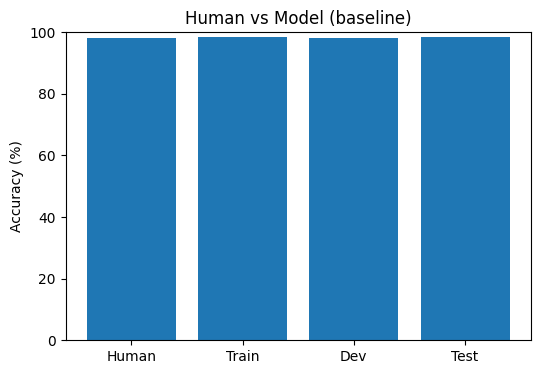

In [7]:
metrics = {
    "Human": HUMAN_ACCURACY,
    "Train": baseline_train_acc,
    "Dev":   baseline_dev_acc,
    "Test":  baseline_test_acc
}

plt.figure(figsize=(6,4))
plt.bar(list(metrics.keys()), list(metrics.values()))
plt.ylim(0, 100)
plt.ylabel("Accuracy (%)")
plt.title("Human vs Model (baseline)")
plt.show()

completed_viz = True


## 7) 🧩 Assignment: Implement Hyperparameter Search (lr × weight_decay)

**🇷🇺 Что нужно сделать:**  
Реализуйте перебор гиперпараметров `lr × weight_decay`, обучите модели и выберите лучшую по **Dev accuracy**.  
Сохраните все результаты в `student_search_results` и лучшую конфигурацию — в `student_best`.

**Требования:**  
- Перебрать каждую пару `(lr, weight_decay)`.  
- Для каждой пары обучить модель `epochs=SEARCH_EPOCHS`.  
- Сохранить для каждой пары: `{"lr","wd","train_acc","dev_acc","test_acc"}`.  
- Итог: `student_best = {"lr","wd","train_acc","dev_acc","test_acc"}` с максимальной `dev_acc`.

**🇬🇧 What to do:**  
Implement a grid over `lr × weight_decay`, train models, and pick the best by **Dev accuracy**.  
Store all runs in `student_search_results` and the winner in `student_best`.

**Requirements:**  
- Iterate over every `(lr, weight_decay)` pair.  
- Train for `epochs=SEARCH_EPOCHS` for each pair.  
- Save for each run: `{"lr","wd","train_acc","dev_acc","test_acc"}`.  
- Final: `student_best = {"lr","wd","train_acc","dev_acc","test_acc"}` with the highest `dev_acc`.


In [8]:
SEARCH_EPOCHS = 3
LRS = [1e-4, 5e-4, 1e-3]
WDS = [0.0, 1e-4, 1e-3]

student_search_results = []
student_best = None

for lr in LRS:
    for wd in WDS:
        model, tr_acc, dv_acc, ts_acc = train_model(epochs=SEARCH_EPOCHS, lr=lr, weight_decay=wd)
        run = {"lr": lr, "wd": wd, "train_acc": tr_acc, "dev_acc": dv_acc, "test_acc": ts_acc}
        student_search_results.append(run)
        if (student_best is None) or (dv_acc > student_best["dev_acc"]):
            student_best = run

print(f"Total runs: {len(student_search_results)}")
print("Top by Dev:", student_best)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 01 | loss=1.0061 | dev_acc=88.41%


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 02 | loss=0.3160 | dev_acc=92.10%


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 03 | loss=0.2345 | dev_acc=93.53%


... (46 outputs left out)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 03 | loss=0.0664 | dev_acc=97.98%


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Total runs: 9
Top by Dev: {'lr': 0.001, 'wd': 0.0001, 'train_acc': 98.54, 'dev_acc': 98.21, 'test_acc': 98.5}



## 8) 🧩 Assignment: Bias/Variance *after* Optimization

**🇷🇺 Что нужно сделать:**  
Используя `student_best`, пересчитайте **avoidable bias** и **variance**, визуализируйте Human vs Train*/Dev*/Test*.

**🇬🇧 What to do:**  
Using `student_best`, recompute **avoidable bias** and **variance**, and visualize Human vs Train*/Dev*/Test*.


After optimization -> Dev: 98.21% | Test: 98.50%
Avoidable bias: -0.54 pp | Variance: -0.33 pp


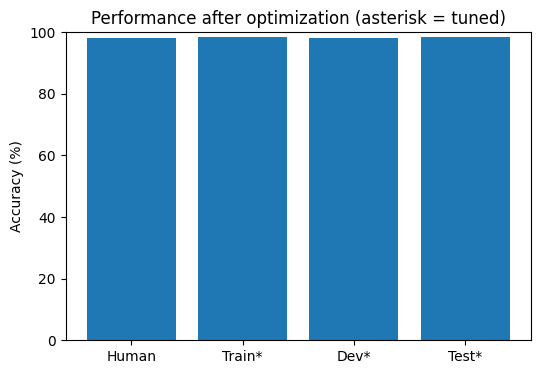

In [9]:
opt_avoidable_bias = HUMAN_ACCURACY - student_best["train_acc"]
opt_variance = student_best["dev_acc"] - student_best["train_acc"]

print(f"After optimization -> Dev: {student_best['dev_acc']:.2f}% | Test: {student_best['test_acc']:.2f}%")
print(f"Avoidable bias: {opt_avoidable_bias:.2f} pp | Variance: {opt_variance:.2f} pp")

plt.figure(figsize=(6,4))
plt.bar(["Human","Train*","Dev*","Test*"],
        [HUMAN_ACCURACY, student_best["train_acc"], student_best["dev_acc"], student_best["test_acc"]])
plt.ylim(0, 100)
plt.ylabel("Accuracy (%)")
plt.title("Performance after optimization (asterisk = tuned)")
plt.show()


## 9) 🧩 Assignment: Reflection (RU/EN)

**🇷🇺 Напишите короткие ответы (≥ 2–3 предложения на пункт):**  
1) Почему после превышения уровня человека **human-level** перестаёт быть потолком?  
2) Почему человеческий уровень — не конечный предел?  
3) Примеры систем, превзошедших человека и почему.

**🇬🇧 Write short answers (≥ 2–3 sentences each):**  
1) Why does *human-level* stop being a ceiling once surpassed?  
2) Why is human performance not the final limit?  
3) Examples of systems surpassing humans and why.


In [10]:
REFLECTION = {
    "when_surpass_human_stop_using_human_as_ceiling":
    "Как только модель начинает превосходить человека, использовать человеческий уровень как потолок уже нет смысла. Мы же уже доказали, что модель может делать лучше. Теперь человеческий результат — это просто нижняя планка, а не верхний предел. Наша задача — понять, какие реальные границы есть у этой задачи и как далеко может зайти модель.",

    "why_human_not_final_limit":
    "Человеческий уровень — это не конечный предел, потому что у машин есть преимущества, которых нет у людей: они могут обрабатывать огромные объёмы данных, не устают, работают быстрее и видят закономерности, которые человек просто не замечает. Мы ограничены биологией, а машины — только мощностью вычислений и качеством данных.",

    "examples_surpassing_human":
    "Примеров много: Системы распознавания изображений на ImageNet уже достигли >98% точности, тогда как люди — около 95%; AlphaGo обыграл чемпиона мира по Го — игре, где считалось, что ИИ никогда не превзойдёт человека; Медицинские ИИ сейчас диагностируют некоторые болезни по снимкам лучше врачей. Всё это возможно благодаря способности машин находить сложные паттерны в больших данных и работать без ошибок и усталости."
}
print("Reflection answers recorded.")
completed_reflection = True

Reflection answers recorded.



### Extra A) Error Analysis
**RU:** Выведите 12–16 неверных предсказаний Dev и обсудите паттерны.  
**EN:** Show 12–16 wrong Dev predictions and discuss patterns.


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


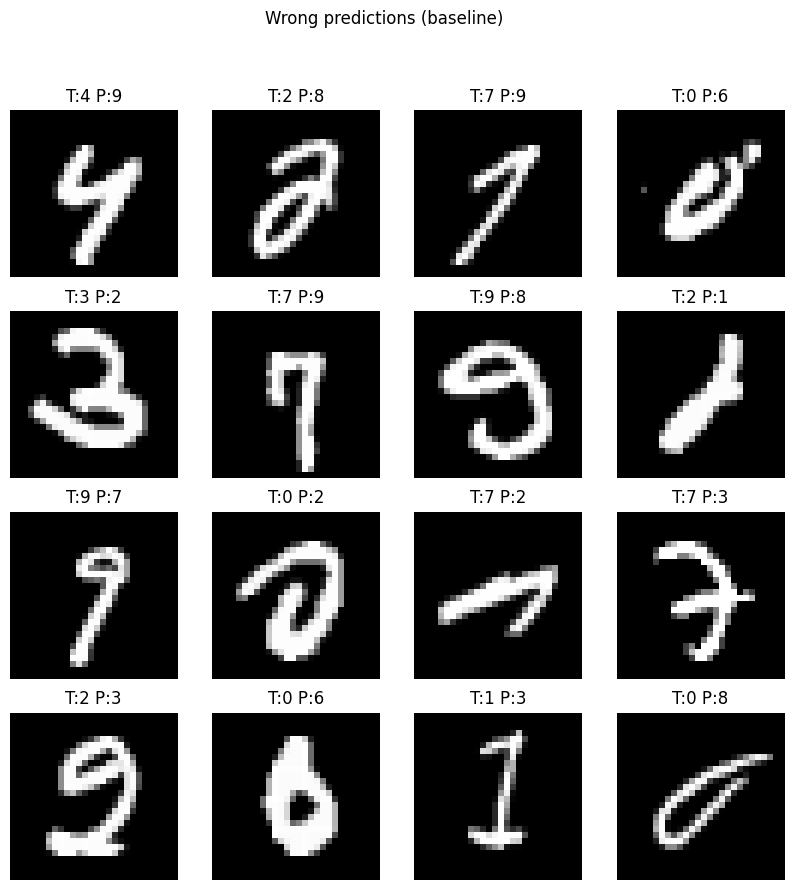

In [12]:

# @title Extra A) Error Analysis (show wrong predictions)
def collect_wrong_preds(model, loader, max_items=16):
    model.eval()
    wrong = []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            preds = torch.argmax(logits, dim=1)
            mask = preds != yb
            idxs = torch.where(mask)[0]
            for i in idxs:
                wrong.append((xb[i].cpu(), int(yb[i].cpu()), int(preds[i].cpu())))
                if len(wrong) >= max_items:
                    return wrong
    return wrong

wrong = collect_wrong_preds(baseline_model, dev_loader, max_items=16)
cols = 4
rows = max(1, math.ceil(len(wrong)/cols))
plt.figure(figsize=(10, 2.5*rows))
for i, item in enumerate(wrong):
    img, y_true, y_pred = item
    plt.subplot(rows, cols, i+1)
    plt.imshow(img.squeeze(0), cmap="gray")
    plt.title(f"T:{y_true} P:{y_pred}")
    plt.axis("off")
plt.suptitle("Wrong predictions (baseline)")
plt.show()


### Extra B) Simple Augmentation
**RU:** Попробуйте лёгкие аугментации (`RandomRotation`) и сравните метрики.  
**EN:** Try light augmentation (`RandomRotation`) and compare metrics.


In [13]:

# @title Extra B) Simple Augmentation (try & compare)
aug_transform = T.Compose([T.RandomRotation(10), T.ToTensor()])
train_full_aug = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=aug_transform)
train_ds_aug, _ = random_split(train_full_aug, [50_000, len(train_full_aug)-50_000],
                               generator=torch.Generator().manual_seed(SEED))
train_loader_aug = DataLoader(train_ds_aug, batch_size=BATCH, shuffle=True, num_workers=2, pin_memory=True)

def train_model_with_loader(train_loader, epochs=3, lr=1e-3, weight_decay=0.0):
    model = SmallCNN().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_dev = -1.0
    best_state = None
    for ep in range(1, epochs+1):
        train_one_epoch(model, train_loader, opt)
        dv = evaluate(model, dev_loader)
        if dv > best_dev:
            best_dev = dv
            best_state = {k:v.cpu() for k,v in model.state_dict().items()}
        print(f"[AUG] Epoch {ep:02d} | dev_acc={dv:.2f}%")
    model.load_state_dict({k:v.to(DEVICE) for k,v in best_state.items()})
    return model, evaluate(model, train_loader), evaluate(model, dev_loader), evaluate(model, test_loader)

aug_model, aug_tr, aug_dv, aug_ts = train_model_with_loader(train_loader_aug, epochs=3, lr=1e-3, weight_decay=0.0)
print(f"\nAugmented => Train:{aug_tr:.2f}% Dev:{aug_dv:.2f}% Test:{aug_ts:.2f}%")
print("Compare with baseline -> Dev:{:.2f}% Test:{:.2f}%".format(baseline_dev_acc, baseline_test_acc))

[AUG] Epoch 01 | dev_acc=96.61%


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


[AUG] Epoch 02 | dev_acc=97.77%


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


[AUG] Epoch 03 | dev_acc=97.91%


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



Augmented => Train:97.83% Dev:97.91% Test:97.93%
Compare with baseline -> Dev:98.04% Test:98.32%
